In [1]:
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scvi
import numpy as np
import matplotlib.pyplot as plt
from lightning.pytorch import seed_everything

seed_everything(12345)

import os
import bbknn
from scipy import sparse
import matplotlib.pyplot as plt

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_n

In [2]:
adata = sc.read("./visiumHD_overall.h5ad")

In [3]:
#adata = adata2[adata2.obs['domain'] == 'peri_tumor'].copy()
adata.obsm['spatial'] = adata.obsm['X_spatial']

In [4]:
sc.pp.filter_genes(adata, min_counts=3)
sc.pp.filter_cells(adata, min_counts=20)
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)
adata.obs['batch'] = 1 ### Set batch to 1

In [6]:
scvi.model.SCVI.setup_anndata(
    adata, 
    layer="counts", 
    batch_key='batch',
)

model = scvi.model.SCVI(adata)
model.train(early_stopping=True, enable_progress_bar=True)
adata.obsm['X_scVI'] = model.get_latent_representation(adata).astype(np.float32)

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/scvi/dataloaders/_data_splitting.py:258: UserWarning: 2 cells moved from training set to validation set. if you want to avoid it please use train_size parameter during train.
  self.n_train, self.n_val = validate_data_split(
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA RTX 2000 Ada Generation Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/g

Training:   0%|          | 0/65 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=65` reached.


In [7]:
# Select the neiborhood range
sq.gr.spatial_neighbors(adata, library_key='group', coord_type='generic', delaunay=False,
                        radius=60,
                        spatial_key='spatial', percentile=99)
#cc.gr.remove_long_links(adata,distance_percentile = 95.0)



In [8]:
cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep='X_scVI', out_key='X_cellcharter', sample_key='group')
autok = cc.tl.ClusterAutoK(
    n_clusters=(2,10), 
    max_runs=10,
    convergence_tol=0.001
)

#adata.write('./af_region.h5ad')

  0%|          | 0/11 [00:00<?, ?it/s]

In [9]:
autok.fit(adata, use_rep='X_cellcharter')

Iteration 1/10


  0%|          | 0/11 [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVIC

Iteration 2/10


  0%|          | 0/11 [00:00<?, ?it/s]

...

  0%|          | 0/11 [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVIC

Iteration 10/10


  0%|          | 0/11 [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVIC

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


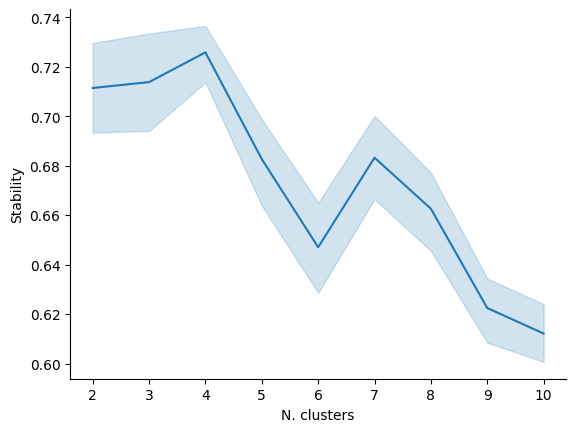

In [10]:
cc.pl.autok_stability(autok)
adata.obs['cluster_cellcharter'] = autok.predict(adata, use_rep='X_cellcharter')


In [11]:
adata.obsm['spatial'] = adata.obsm['spatial'].astype(np.float64)# Convert coordinates to float
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata

AnnData object with n_obs × n_vars = 122597 × 15288
    obs: 'orig.ident', 'nCount_Spatial.Polygons', 'nFeature_Spatial.Polygons', 'group', 'nCount_Spatial', 'nFeature_Spatial', 'Cell_Anno', 'Type', 'barcode', 'n_counts', 'batch', '_scvi_batch', '_scvi_labels', 'cluster_cellcharter'
    var: 'n_counts'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors'
    obsm: 'X_spatial', 'spatial', 'X_scVI', 'X_cellcharter'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [12]:
adata.obs['cluster_cellcharter']

cellid_000006355-1    3
cellid_000006358-1    3
cellid_000006361-1    0
cellid_000006362-1    3
cellid_000006363-1    0
                     ..
cellid_000299358-1    2
cellid_000299363-1    3
cellid_000299370-1    2
cellid_000299375-1    3
cellid_000299377-1    3
Name: cluster_cellcharter, Length: 122597, dtype: category
Categories (4, object): ['0', '1', '2', '3']

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


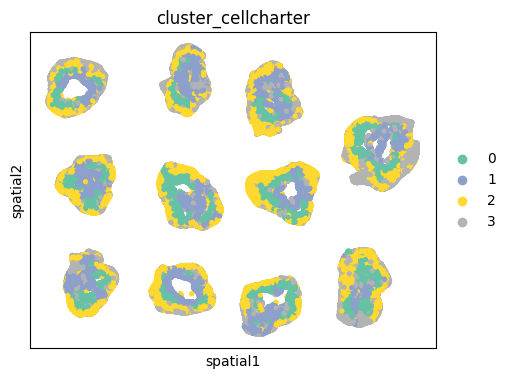

In [13]:
sq.pl.spatial_scatter(
    adata, 
    color=['cluster_cellcharter'], 
    library_key='batch',  
    size=30, 
    img=None, shape=None,
    palette='Set2',
    figsize=(5,5),
    ncols=1
)

In [14]:
print(adata.obs['cluster_cellcharter'].value_counts())

cluster_cellcharter
2    47208
1    28973
0    26361
3    20055
Name: count, dtype: int64


In [17]:
replace_dict = {
    '0': 'niche1',
    '1': 'niche2',
    '2': 'niche3',
    '3': 'niche4'
}

# Perform the replacement
adata.obs['cluster_cellcharter'] = adata.obs['cluster_cellcharter'].replace(replace_dict)

output_df = pd.DataFrame({
    'Barcode': adata.obs_names,  # Cell names correspond to AnnData obs_names
    'Niche': adata.obs['cluster_cellcharter']  # Grouping information comes from the cluster_cellcharter column
})

# Save as a CSV file (a custom filename is allowed, e.g. 'cell_group_info.csv')
output_df.to_csv('./visiumHD niche.csv', index=False)

In [28]:
############## Start here after computing the neighborhood
#adata.write("./visiumHD_spatial_analysis.h5ad")
#adata = sc.read("./visiumHD scniche.h5ad")

In [12]:
adata.obsm['spatial'] = adata.obsm['X_spatial']
sc.pp.filter_genes(adata, min_counts=3)
sc.pp.filter_cells(adata, min_counts=20)
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)
adata.obs['batch'] = 1 ### Set batch to 1
sq.gr.spatial_neighbors(adata, library_key='group', coord_type='generic', delaunay=False,
                        radius=60,
                        spatial_key='spatial', percentile=99)
adata


AnnData object with n_obs × n_vars = 122372 × 15284
    obs: 'orig.ident', 'nCount_Spatial.Polygons', 'nFeature_Spatial.Polygons', 'group', 'nCount_Spatial', 'nFeature_Spatial', 'Cell_Anno', 'Type', 'niche', 'Celltype', 'celltype', 'barcode', 'condition', 'n_counts', 'batch'
    var: 'n_counts'
    uns: 'Cell_Anno_colors', 'log1p', 'spatial_neighbors'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [13]:

celltype_colors = {
    'EC': '#d51f26',
    'T cell': "#0F7240",
    'LAMs': "#FCCC3A",
    'Res Mac': "#d5a339",
    'Inf Mac': '#f3758a',
    'DCs': '#C67052',
    'Mono': '#F49E47',
    'Cycling Myeloid': '#C0937E',
    'SC': '#5d2b84',
    'vSMCs':'#9d9ac6',
    'FBs C1': '#b1ddcc','FBs C2': '#00a7fa','FBs C3': '#92B2D8','FBs C4': '#C9E1AF',
    'FBs C5': '#bbe379','FBs C6': '#b9e6fb','FBs C7': '#7AA15E','FBs C8': '#31aaaa'
    
}

# Ensure Celltype is a categorical variable
if not isinstance(adata.obs['Cell_Anno'].dtype, pd.CategoricalDtype):
    adata.obs['Cell_Anno'] = pd.Categorical(adata.obs['Cell_Anno'])

# Store the colors into adata.uns in category order
categories = adata.obs['Cell_Anno'].cat.categories
adata.uns['Cell_Anno_colors'] = [celltype_colors[cat] for cat in categories]

adata.obs['Type'].unique()
adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')

In [8]:
adata.obs['niche']

cellid_000006355-1    niche4
cellid_000006358-1    niche4
cellid_000006361-1    niche1
cellid_000006362-1    niche4
cellid_000006363-1    niche1
                       ...  
cellid_000299358-1    niche3
cellid_000299363-1    niche4
cellid_000299370-1    niche3
cellid_000299375-1    niche4
cellid_000299377-1    niche4
Name: niche, Length: 122372, dtype: category
Categories (4, object): ['niche1', 'niche2', 'niche3', 'niche4']

In [29]:
#adata_subgroup1 = adata[adata.obs['banksy_niche'] == 'niche_3']
#adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')
#adata_subgroup1 = adata[adata.obs['banksy_niche'].isin(['niche_1', 'niche_4', 'niche_6', 'niche_7'])].copy()
adata_subgroup1 = adata[adata.obs['niche'] == 'niche2']


/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/cellcharter/gr/_nhood.py:236: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{cluster_key}_nhood_enrichment"] = result


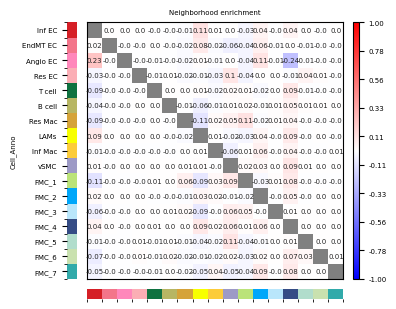

In [15]:
cc.gr.nhood_enrichment(
    adata_subgroup1,
    cluster_key='Cell_Anno',###
)

cc.pl.nhood_enrichment(
    adata_subgroup1,
    cluster_key='Cell_Anno',
    annotate=True,
    vmin=-1,
    vmax=1,
    figsize=(3,3),
    fontsize=5,
)
plt.savefig('./CWD neiborhood.pdf', bbox_inches='tight',  dpi=500 )
#### y-axis is source, x-axis is target (or neighborhood)

In [21]:
adata

AnnData object with n_obs × n_vars = 28963 × 15284
    obs: 'orig.ident', 'nCount_Spatial.Polygons', 'nFeature_Spatial.Polygons', 'group', 'nCount_Spatial', 'nFeature_Spatial', 'Cell_Anno', 'Type', 'niche', 'Celltype', 'celltype', 'barcode', 'condition', 'n_counts', 'batch'
    var: 'n_counts'
    uns: 'Cell_Anno_colors', 'log1p', 'spatial_neighbors', 'Cell_Anno_condition_diff_nhood_enrichment'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [31]:
# Compute neighborhood differences
adata_subgroup1.obs['condition'] = adata_subgroup1.obs['Type'].str.split('-').str[0].astype('category')
cc.gr.diff_nhood_enrichment(
    adata_subgroup1,
    cluster_key='Cell_Anno',
    condition_key='condition',
    library_key='Type',
    pvalues=True,
    n_jobs=10,
    n_perms=100
)

/tmp/ipykernel_738/1171324318.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_subgroup1.obs['condition'] = adata_subgroup1.obs['Type'].str.split('-').str[0].astype('category')


  0%|          | 0/100 [00:00<?, ?it/s]

In [32]:
# Plot
cc.pl.diff_nhood_enrichment(
    adata_subgroup1,
    cluster_key='Cell_Anno',
    condition_key='condition',
    condition_groups=['MP', 'CON'],
    annotate=True,
    figsize=(3,3),
    significance=0.05,
    fontsize=5
)
plt.savefig( './niche2_diff_enrich.pdf',  bbox_inches='tight',  dpi=500)
plt.close() ## Do not display the figure (displaying causes a bug) 1